Disable just-in-time compilation with XLA.

no uniform points
Compiling model...
'compile' took 0.000380 s

Training model...

Step      Train loss    Test loss     Test metric   
0         [1.57e+00]    [1.52e+00]    [1.22e+00]    
1000      [1.51e-05]    [1.46e-05]    [2.33e-03]    
2000      [2.91e-07]    [2.92e-07]    [1.45e-04]    
3000      [2.39e-07]    [2.40e-07]    [1.28e-04]    
4000      [1.74e-07]    [1.76e-07]    [1.07e-04]    
5000      [7.20e-08]    [7.41e-08]    [6.22e-05]    
6000      [2.47e-08]    [2.42e-08]    [1.97e-05]    
7000      [3.60e-08]    [3.17e-08]    [3.83e-05]    
8000      [5.24e-08]    [4.63e-08]    [5.35e-05]    
9000      [1.39e-04]    [1.34e-04]    [1.10e-02]    
10000     [7.74e-06]    [7.40e-06]    [2.59e-03]    

Best model at step 6000:
  train loss: 2.47e-08
  test loss: 2.42e-08
  test metric: [1.97e-05]

'train' took 30.585311 s

Saving loss history to /root/shared/UQ/Tensor-PINNs/Schrodinger/loss.dat ...
Saving training data to /root/shared

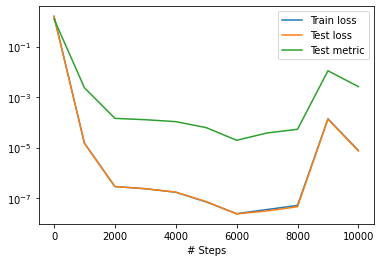

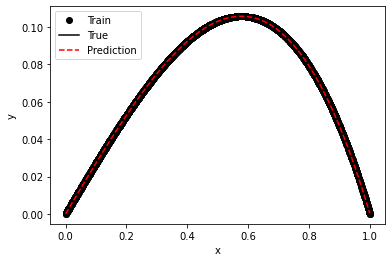

Theta:=  7801


In [3]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()
from deepxde.backend import tf
from functools import reduce
import argparse

parser = argparse.ArgumentParser(description='Set parameters')

k=1
epochs = 10000
seed = 1234

dde.config.set_random_seed(seed)

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    
"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

sigma = 1
N = 4000
N_test = 1000
lambd = 1
kappa = 0

#geom = dde.geometry.Interval(0, np.pi)
geom = dde.geometry.Interval(0, 1)
Geom = GeometryXGeometry(geom, k)

def func(x):
    u_list = [-1/6 * x[:, i:i+1] * (x[:, i:i+1] ** 2 - 1) for i in range(k)]
    u = reduce(lambda x1, x2: x1 * x2, u_list)
    c = np.exp(1/2 * k ** 2 * sigma ** 2)
    return c * u

def pde(x, y):
    dy_xx = dde.grad.hessian(y, x)
    
    dy1 = - dde.grad.hessian(y, x, i=0, j=0)
    c = tf.exp(1/2 * k ** 2 * sigma ** 2) 
    
    u = func(x)    
    F_list = [c * x[:, 0:1] - lambd * u ** 3 - kappa ** 2 * u]
    
    A = dy1 - lambd * y ** 3 - kappa ** 2 * y
    C = reduce(lambda x1, x2: x1 * x2, F_list)
    return A - C

data = dde.data.PDE(Geom, pde, [], train_distribution="pseudo", num_domain=N, solution=func, num_test=N_test)


layer_size = [k] + [50] * 4 + [1]
activation = 'tanh'
initializer = 'Glorot uniform'
net = dde.nn.FNN(layer_size, activation, initializer)

def output_transform(x, y):
    transf_list = [x[:, i:i+1] * (x[:, i:i+1] - 1) for i in range(k)]
    transf = reduce(lambda x1, x2: x1 * x2, transf_list)
    return transf * y

net.apply_output_transform(output_transform)

model = dde.Model(data, net)
model.compile("adam", lr=1e-3, metrics=["l2 relative error"])
#model.compile("adam", lr=1e-4, decay = ("inverse time", 5000, 0.5), metrics=["l2 relative error"])

losshistory, train_state = model.train(epochs=epochs)

dde.saveplot(losshistory, train_state, issave=True, isplot=True)
 
result = np.sum(
            [np.prod(v.get_shape().as_list()) for v in __import__('tensorflow').compat.v1.trainable_variables()]
        )
print('Theta:= ', result)
#print("# Parameters:", np.sum([np.prod(v.get_shape().as_list()) for v in __import__('tensorflow').compat.v1.trainable_variables()]))


x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(k)]
xx = np.concatenate(x_list).T
sol = func(xx)
pred = model.predict(xx)

name = 'results/diag_pred' + str(k) 
test = np.save(name,pred)

name = 'results/diag_exact' + str(k) 
test = np.save(name,sol)

name = 'results/diag_x' + str(k) 
test = np.save(name,xx[:, 0:1])






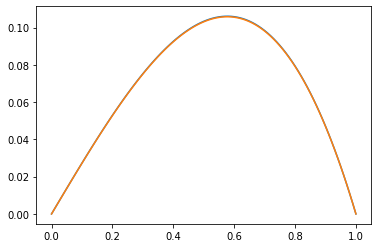

In [4]:
from matplotlib import pyplot as plt

plt.plot(x.ravel(),pred.ravel(), label='pred')
plt.plot(x.ravel(),sol.ravel(), label='exact')